# Phase 3A Step 10 — Comprehensive Correlation and Association Analysis

## Customer Retention Intelligence System

This independent notebook measures pairwise relationships in the configured IBM Telco
**development split only**. It covers numerical correlation, categorical association,
categorical–numerical association, and exploratory marginal mutual information. It does
not perform hypothesis testing, causal inference, VIF analysis, outlier handling, feature
selection, class balancing, or predictive modelling.

All encodings are temporary notebook objects. No transformed data or fitted preprocessing
artifact is persisted.

## 1. Independent setup and leakage-safe loading

The project root is detected from marker files and configuration is loaded through the
project utility. The configured path must equal `data/processed/development.parquet`
before any data read. Previous notebooks are not imported or executed.

In [1]:
# ruff: noqa: E501
import importlib.metadata as metadata
import sys
from pathlib import Path


def find_project_root(start: Path) -> Path:
    # Return the nearest parent containing the project marker files.
    start = start.resolve()
    for candidate in (start, *start.parents):
        if (candidate / "pyproject.toml").is_file() and (candidate / "params.yaml").is_file():
            return candidate
    raise FileNotFoundError("Could not locate project root.")


PROJECT_ROOT = find_project_root(Path.cwd())
SRC_PATH = PROJECT_ROOT / "src"
if str(SRC_PATH) not in sys.path:
    sys.path.insert(0, str(SRC_PATH))

from retention.utils.config import load_config  # noqa: E402

config = load_config(PROJECT_ROOT / "params.yaml")
configured_development_path = Path(config["data"]["development_path"])
assert configured_development_path == Path("data/processed/development.parquet")
development_path = (PROJECT_ROOT / configured_development_path).resolve()
assert development_path.is_file()

print(f"Project root: {PROJECT_ROOT}")
print(f"Input: {configured_development_path}")
print(f"Python: {sys.version.split()[0]} ({sys.executable})")
print(f"Configured random state: {config['project']['random_state']}")
for package in ["pandas", "numpy", "scipy", "scikit-learn", "matplotlib", "seaborn", "pyarrow"]:
    print(f"{package}: {metadata.version(package)}")

Project root: /Users/harshagarwal/Projects/ChurnRatePredictor
Input: data/processed/development.parquet
Python: 3.11.14 (/Users/harshagarwal/Projects/ChurnRatePredictor/.venv/bin/python)
Configured random state: 42
pandas: 2.3.3
numpy: 2.4.6
scipy: 1.17.1
scikit-learn: 1.9.1
matplotlib: 3.11.2
seaborn: 0.13.2
pyarrow: 26.0.1


In [2]:
# ruff: noqa: E501
import hashlib

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
from IPython.display import display
from sklearn.feature_selection import mutual_info_classif

pd.set_option("display.max_columns", None)
pd.set_option("display.max_rows", 300)
pd.set_option("display.float_format", lambda value: f"{value:,.4f}")
sns.set_theme(style="whitegrid", context="notebook", palette="colorblind")
plt.rcParams.update({"figure.dpi": 110, "axes.titleweight": "bold", "axes.labelsize": 11})

df = pd.read_parquet(development_path)
target_column = config["data"]["target_column"]
identifier_column = config["data"]["id_column"]
random_state = int(config["project"]["random_state"])
numerical_features = ["tenure", "MonthlyCharges", "TotalCharges"]
categorical_features = [
    "gender", "SeniorCitizen", "Partner", "Dependents", "PhoneService",
    "MultipleLines", "InternetService", "OnlineSecurity", "OnlineBackup",
    "DeviceProtection", "TechSupport", "StreamingTV", "StreamingMovies",
    "Contract", "PaperlessBilling", "PaymentMethod",
]
predictor_features = numerical_features + categorical_features

assert df.shape == (5_634, 21)
assert set(df[target_column].unique()) == {"No", "Yes"}
assert identifier_column not in predictor_features and target_column not in predictor_features
assert df[numerical_features].notna().all().all()

print(f"Development data: {df.shape[0]:,} rows × {df.shape[1]} columns")
print("Numerical predictors:", numerical_features)
print("Categorical predictors (including SeniorCitizen):", categorical_features)
display(df.head())

Development data: 5,634 rows × 21 columns
Numerical predictors: ['tenure', 'MonthlyCharges', 'TotalCharges']
Categorical predictors (including SeniorCitizen): ['gender', 'SeniorCitizen', 'Partner', 'Dependents', 'PhoneService', 'MultipleLines', 'InternetService', 'OnlineSecurity', 'OnlineBackup', 'DeviceProtection', 'TechSupport', 'StreamingTV', 'StreamingMovies', 'Contract', 'PaperlessBilling', 'PaymentMethod']


,customerID,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,OnlineBackup,DeviceProtection,TechSupport,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges,Churn
0,5334-JLAXU,Female,0,Yes,No,60,Yes,Yes,Fiber optic,Yes,Yes,No,No,No,Yes,Month-to-month,Yes,Credit card (automatic),94.1000,"5,475.9000",No
1,4573-JKNAE,Male,0,No,Yes,12,Yes,No,No,No internet service,No internet service,No internet service,No internet service,No internet service,No internet service,Two year,No,Bank transfer (automatic),19.3500,212.3000,No
2,6923-JHPMP,Female,0,No,No,2,Yes,No,Fiber optic,Yes,No,Yes,No,No,No,Month-to-month,Yes,Electronic check,80.4500,137.1000,No
3,5524-KHNJP,Male,0,Yes,Yes,33,Yes,No,DSL,Yes,No,Yes,No,Yes,Yes,One year,No,Credit card (automatic),74.7500,"2,453.3000",No
4,5433-KYGHE,Female,0,No,Yes,14,Yes,Yes,Fiber optic,Yes,No,No,Yes,No,No,Month-to-month,Yes,Mailed check,86.0000,"1,164.0500",No


# 2. Statistical fundamentals

**Correlation** is a standardized numerical measure of how two quantitative variables
co-vary. **Association** is broader: any dependence between variables, including
relationships between categories or between a category and a number.

- A **linear** relationship follows an approximately straight-line trend; a **monotonic**
  relationship only requires values to tend consistently upward or downward. It may curve.
- Positive correlation means larger values of one variable tend to accompany larger
  values of the other; negative correlation means they tend to move in opposite directions.
- Magnitude describes observed relationship strength. Statistical significance concerns
  sampling evidence under a null model. A tiny coefficient can be significant in a large
  sample, while a practically large estimate can be uncertain in a small sample. This
  notebook reports no p-values and performs no formal significance tests.
- Correlation does not establish causation. Confounding, selection, common causes, reverse
  direction, and structural definitions can all create association.
- **Predictor redundancy** occurs when predictors carry overlapping information.
  **Multicollinearity** is strong linear dependence among regression predictors; it can
  destabilize coefficient estimates without necessarily harming prediction. VIF is outside
  this step.

Different variable types encode different information. Pearson needs quantitative scales;
rank coefficients need order; Cramér's V and Phi use counts for categories; Eta compares
numerical distributions across groups; mutual information can capture general dependency.

Arbitrary integer codes for nominal labels create a fictitious order and spacing. Coding
`DSL=0`, `Fiber=1`, `No=2` and applying Pearson would make results depend on the chosen
label order, not just the data. Such codes are acceptable as temporary discrete labels for
an estimator that treats them as categories, but not as quantitative magnitudes.

In [3]:
# ruff: noqa: E501
def annotated_heatmap(matrix: pd.DataFrame, title: str, cmap: str = "vlag", center: float | None = 0, vmin: float | None = -1, vmax: float | None = 1, figsize: tuple[float, float] = (7.5, 5.8), fmt: str = ".3f") -> None:
    # Plot a consistently styled annotated matrix.
    fig, axis = plt.subplots(figsize=figsize)
    sns.heatmap(matrix, annot=True, fmt=fmt, cmap=cmap, center=center, vmin=vmin, vmax=vmax, square=True, linewidths=0.5, cbar_kws={"shrink": 0.8}, ax=axis)
    axis.set_title(title, pad=12)
    plt.xticks(rotation=35, ha="right")
    plt.yticks(rotation=0)
    plt.tight_layout()
    plt.show()


def assert_symmetric_association(matrix: pd.DataFrame, diagonal: float = 1.0) -> None:
    # Verify finite symmetric association matrices and their expected diagonal.
    values = matrix.to_numpy(dtype=float)
    assert np.isfinite(values).all()
    assert np.allclose(values, values.T, atol=1e-12)
    assert np.allclose(np.diag(values), diagonal, atol=1e-12)

# 3. Pearson correlation

For quantitative variables $X$ and $Y$, Pearson's sample correlation is

$$r=\frac{\sum_{i=1}^{n}(x_i-\bar{x})(y_i-\bar{y})}
{\sqrt{\sum_{i=1}^{n}(x_i-\bar{x})^2}\sqrt{\sum_{i=1}^{n}(y_i-\bar{y})^2}}.$$

It measures standardized **linear** association from $-1$ to $1$. Its direction comes from
the covariance sign. It is sensitive to extreme values and can be near zero for a strong
but non-linear, non-monotonic relationship. A high value neither proves causation nor says
the variables are interchangeable. Scatterplots and domain structure remain essential.

,tenure,MonthlyCharges,TotalCharges
tenure,1.0000,0.2545,0.8290
MonthlyCharges,0.2545,1.0000,0.6525
TotalCharges,0.8290,0.6525,1.0000


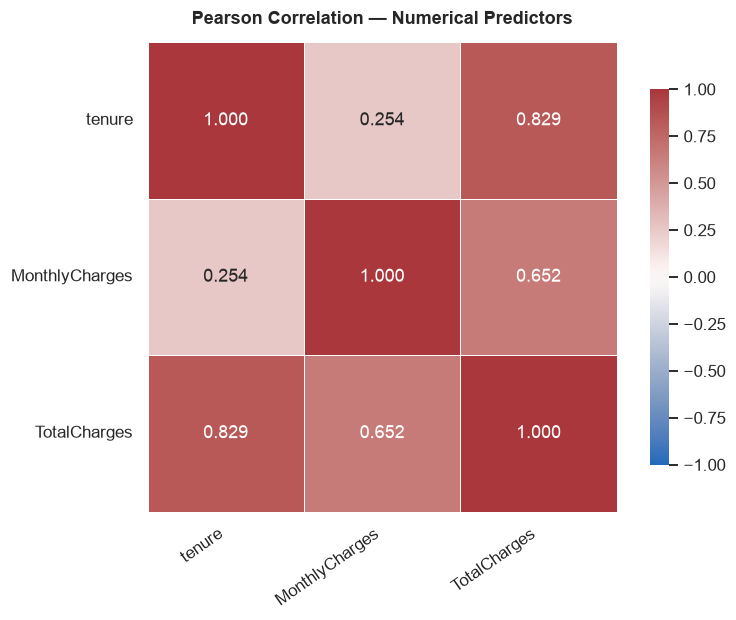

In [4]:
# ruff: noqa: E501
pearson_matrix = df[numerical_features].corr(method="pearson")
assert_symmetric_association(pearson_matrix)
display(pearson_matrix)
annotated_heatmap(pearson_matrix, "Pearson Correlation — Numerical Predictors")

**Observed Pearson findings.** Tenure and TotalCharges have a strong positive linear
association ($r=0.829$). This agrees with accumulated billing: more observed months permit
larger totals, while different monthly prices create the fan-shaped spread seen previously.
MonthlyCharges–TotalCharges is moderately positive ($r=0.652$), and
tenure–MonthlyCharges is weakly positive ($r=0.254$). These are descriptive associations,
not evidence that changing tenure or price causes another quantity or churn.

# 4. Spearman rank correlation

Spearman's coefficient is Pearson correlation applied to ranks:

$$\rho_s=\operatorname{Corr}(R(X),R(Y)).$$

It measures monotonic association, so a consistently increasing curve may score highly
even when it is not linear. Average ranks are assigned to tied values; ties are extensive
for integer tenure and are handled by pandas' rank-based implementation. Ranking reduces
the influence of value magnitude and often reduces sensitivity to extreme observations,
but it is not universally robust to leverage, selection, or measurement error.

Pearson–Spearman differences can suggest curvature, outlier influence, heteroscedasticity,
or ties, but a difference alone does not establish nonlinearity.

,tenure,MonthlyCharges,TotalCharges
tenure,1.0000,0.2834,0.8915
MonthlyCharges,0.2834,1.0000,0.6403
TotalCharges,0.8915,0.6403,1.0000


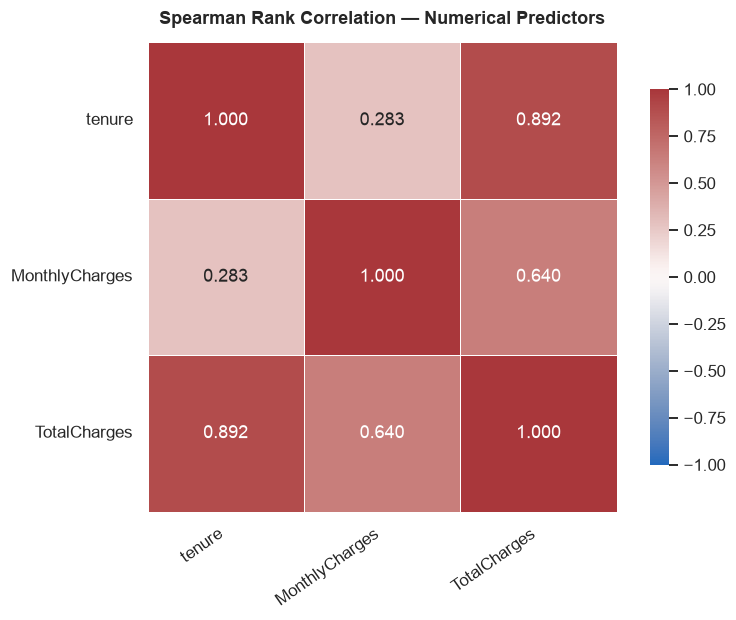

,Pearson,Spearman,Spearman − Pearson
tenure ↔ MonthlyCharges,0.2545,0.2834,0.0289
tenure ↔ TotalCharges,0.8290,0.8915,0.0625
MonthlyCharges ↔ TotalCharges,0.6525,0.6403,-0.0122


In [5]:
# ruff: noqa: E501
spearman_matrix = df[numerical_features].corr(method="spearman")
assert_symmetric_association(spearman_matrix)
display(spearman_matrix)
annotated_heatmap(spearman_matrix, "Spearman Rank Correlation — Numerical Predictors")

pairwise_comparison = pd.DataFrame({
    "Pearson": [pearson_matrix.loc["tenure", "MonthlyCharges"], pearson_matrix.loc["tenure", "TotalCharges"], pearson_matrix.loc["MonthlyCharges", "TotalCharges"]],
    "Spearman": [spearman_matrix.loc["tenure", "MonthlyCharges"], spearman_matrix.loc["tenure", "TotalCharges"], spearman_matrix.loc["MonthlyCharges", "TotalCharges"]],
}, index=["tenure ↔ MonthlyCharges", "tenure ↔ TotalCharges", "MonthlyCharges ↔ TotalCharges"])
pairwise_comparison["Spearman − Pearson"] = pairwise_comparison["Spearman"] - pairwise_comparison["Pearson"]
display(pairwise_comparison)

**Observed Spearman findings.** Tenure–TotalCharges rises to $\rho_s=0.892$, 0.063 above
Pearson, indicating an especially strong increasing rank relationship despite the
fan-shaped, non-constant spread. MonthlyCharges–TotalCharges is $0.640$, close to Pearson;
tenure–MonthlyCharges is $0.283$, also weak. The differences are not large enough to claim
a specific nonlinear form without further diagnostics, and ties in tenure also matter.

# 5. Kendall's Tau-b

For two observations, a pair is **concordant** when their order agrees and **discordant**
when it disagrees. Tau-b adjusts for ties:

$$\tau_b=\frac{C-D}{\sqrt{(C+D+T_X)(C+D+T_Y)}},$$

where $C,D$ are concordant and discordant pair counts and $T_X,T_Y$ count pairs tied only
on one variable. This makes Tau-b appropriate for the tied tenure ranks. Spearman uses
rank covariance and is typically more sensitive to rank distances; Kendall is based on
pair-order probabilities and often has a smaller numerical magnitude. Coefficients from
Pearson, Spearman, and Kendall therefore must not be compared on a common magnitude scale.

,Pearson,Spearman,Kendall Tau-b
tenure ↔ MonthlyCharges,0.2545,0.2834,0.1958
tenure ↔ TotalCharges,0.8290,0.8915,0.7379
MonthlyCharges ↔ TotalCharges,0.6525,0.6403,0.4621


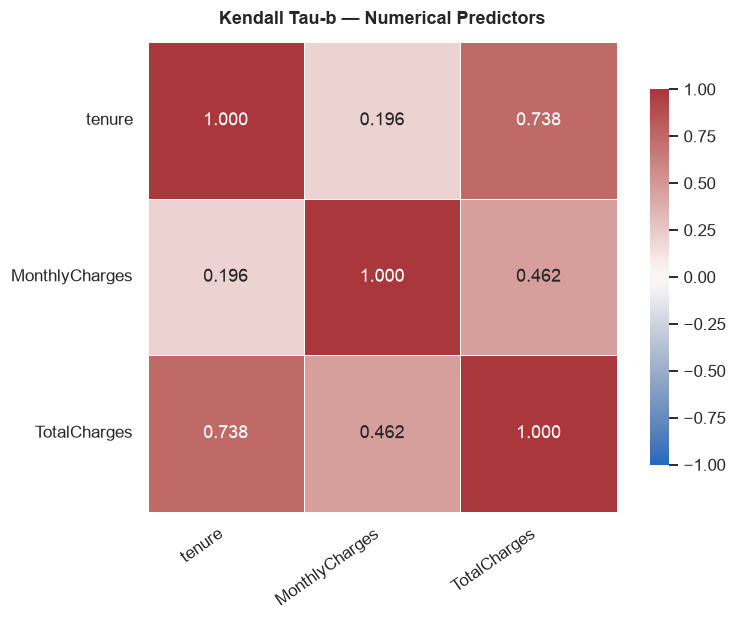

In [6]:
# ruff: noqa: E501
kendall_matrix = df[numerical_features].corr(method="kendall")
assert_symmetric_association(kendall_matrix)

comparison_table = pairwise_comparison[["Pearson", "Spearman"]].copy()
comparison_table["Kendall Tau-b"] = [kendall_matrix.loc["tenure", "MonthlyCharges"], kendall_matrix.loc["tenure", "TotalCharges"], kendall_matrix.loc["MonthlyCharges", "TotalCharges"]]
display(comparison_table)
annotated_heatmap(kendall_matrix, "Kendall Tau-b — Numerical Predictors")

**Observed Kendall findings.** Tau-b is $0.738$ for tenure–TotalCharges, $0.462$ for
MonthlyCharges–TotalCharges, and $0.196$ for tenure–MonthlyCharges. The ordering agrees
with Pearson and Spearman. Its lower values are expected from a different estimand and do
not mean the relationships became weaker after “correction.”

# 6. Point-biserial correlation: numerical predictors versus churn

For binary $Y\in\{0,1\}$ and quantitative $X$, the point-biserial coefficient is

$$r_{pb}=\frac{\bar X_1-\bar X_0}{s_X}\sqrt{pq},$$

where $p$ and $q$ are binary-group proportions. It is exactly Pearson correlation between
$X$ and the documented binary representation. Positive values mean the `Yes=1` group has
a larger mean; negative values mean it has a smaller mean. It standardizes a group mean
difference but does not establish causation or complete class separation.

,mean_retained,mean_churned,point_biserial_r,churned_minus_retained
tenure,37.5489,17.9552,-0.3519,-19.5937
MonthlyCharges,61.6248,74.4677,0.1889,12.8429
TotalCharges,"2,566.5015","1,529.8788",-0.2010,"-1,036.6226"


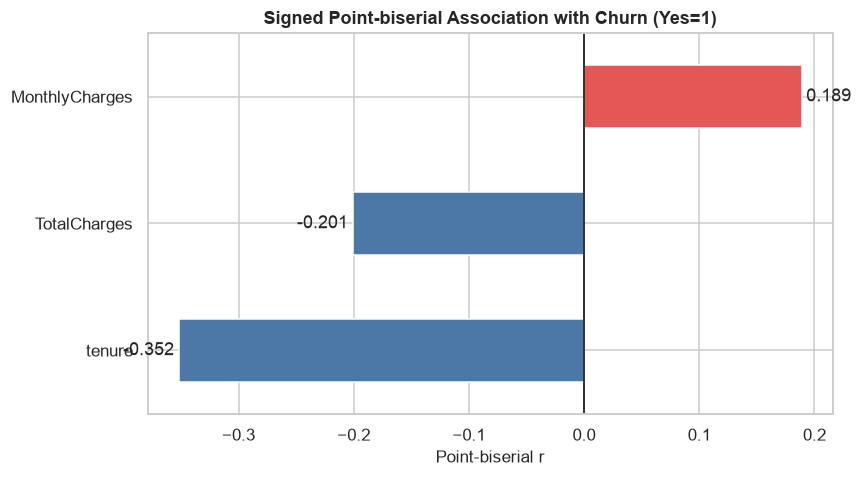

In [7]:
# ruff: noqa: E501
churn_binary = df[target_column].map({"No": 0, "Yes": 1}).astype("int8")
point_biserial = pd.Series({feature: df[feature].corr(churn_binary) for feature in numerical_features}, name="point_biserial_r").sort_values(key=abs, ascending=False)
group_means = df.groupby(target_column, observed=True)[numerical_features].mean().T.rename(columns={"No": "mean_retained", "Yes": "mean_churned"})
point_biserial_table = group_means.join(point_biserial)
point_biserial_table["churned_minus_retained"] = point_biserial_table["mean_churned"] - point_biserial_table["mean_retained"]
display(point_biserial_table)

fig, axis = plt.subplots(figsize=(8, 4.5))
colors = ["#E45756" if value > 0 else "#4C78A8" for value in point_biserial]
point_biserial.sort_values().plot.barh(ax=axis, color=colors)
axis.axvline(0, color="black", linewidth=1)
axis.set(title="Signed Point-biserial Association with Churn (Yes=1)", xlabel="Point-biserial r", ylabel="")
axis.bar_label(axis.containers[0], fmt="%.3f", padding=3)
plt.tight_layout()
plt.show()

**Observed point-biserial findings.** Tenure has the largest absolute coefficient
($r_{pb}=-0.352$): churned customers average 17.96 months versus 37.55 for retained
customers. TotalCharges is negative ($-0.201$; means 1,529.88 versus 2,566.50), consistent
with shorter exposure time. MonthlyCharges is positive ($0.189$; means 74.47 versus
61.62). These signed marginal associations reproduce the earlier bivariate directions but
do not measure adjusted effects or predictive importance.

# 7. Cramér's V: categorical association

A contingency table contains observed counts $O_{ij}$. Under independence, expected counts
are $E_{ij}=n_{i\cdot}n_{\cdot j}/n$, and the chi-square association statistic is

$$\chi^2=\sum_{i,j}\frac{(O_{ij}-E_{ij})^2}{E_{ij}},\qquad
V=\sqrt{\frac{\chi^2/n}{\min(r-1,k-1)}}.$$

Cramér's V normalizes dependence to $[0,1]$ but has no direction. The bias-corrected form
reduces upward finite-sample bias by correcting $\phi^2=\chi^2/n$ and effective table
dimensions. Sparse categories and small expected counts can make estimates unstable; here
we inspect expected-count diagnostics but do not conduct a chi-square hypothesis test or
report p-values.

In [8]:
# ruff: noqa: E501
def cramers_v(x: pd.Series, y: pd.Series, bias_corrected: bool = True) -> float:
    # Calculate conventional or Bergsma-style bias-corrected Cramér's V safely.
    table = pd.crosstab(x, y, dropna=False).to_numpy(dtype=float)
    n = table.sum()
    rows, columns = table.shape
    if n <= 0 or rows < 2 or columns < 2:
        return 0.0
    expected = np.outer(table.sum(axis=1), table.sum(axis=0)) / n
    valid = expected > 0
    chi_square = np.sum(((table - expected) ** 2)[valid] / expected[valid])
    phi_squared = chi_square / n
    if not bias_corrected:
        denominator = min(rows - 1, columns - 1)
        return float(np.sqrt(phi_squared / denominator)) if denominator > 0 else 0.0
    if n <= 1:
        return 0.0
    corrected_phi_squared = max(0.0, phi_squared - ((columns - 1) * (rows - 1)) / (n - 1))
    corrected_rows = rows - ((rows - 1) ** 2) / (n - 1)
    corrected_columns = columns - ((columns - 1) ** 2) / (n - 1)
    denominator = min(corrected_rows - 1, corrected_columns - 1)
    return float(np.sqrt(corrected_phi_squared / denominator)) if denominator > 0 else 0.0


def cramers_matrix(data: pd.DataFrame, columns: list[str], bias_corrected: bool = True) -> pd.DataFrame:
    # Return a symmetric Cramér's V matrix.
    result = pd.DataFrame(np.eye(len(columns)), index=columns, columns=columns)
    for left_index, left in enumerate(columns):
        for right in columns[left_index + 1:]:
            value = cramers_v(data[left], data[right], bias_corrected=bias_corrected)
            result.loc[left, right] = value
            result.loc[right, left] = value
    return result


categorical_with_target = categorical_features + [target_column]
cramers_corrected = cramers_matrix(df, categorical_with_target, bias_corrected=True)
cramers_conventional = cramers_matrix(df, categorical_with_target, bias_corrected=False)
assert_symmetric_association(cramers_corrected)
assert ((cramers_corrected >= 0) & (cramers_corrected <= 1)).all().all()
display(cramers_corrected)

,gender,SeniorCitizen,Partner,Dependents,PhoneService,MultipleLines,InternetService,OnlineSecurity,OnlineBackup,DeviceProtection,TechSupport,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,Churn
gender,1.0000,0.0000,0.0000,0.0000,0.0091,0.0000,0.0022,0.0000,0.0000,0.0000,0.0000,0.0000,0.0000,0.0000,0.0000,0.0056,0.0082
SeniorCitizen,0.0000,1.0000,0.0000,0.2123,0.0000,0.1489,0.2660,0.2220,0.1823,0.1825,0.2269,0.1853,0.1887,0.1456,0.1576,0.1984,0.1526
Partner,0.0000,0.0000,1.0000,0.4474,0.0036,0.1457,0.0000,0.1447,0.1506,0.1537,0.1186,0.1374,0.1229,0.2852,0.0000,0.1580,0.1515
Dependents,0.0000,0.2123,0.4474,1.0000,0.0000,0.0054,0.1658,0.1815,0.1535,0.1476,0.1702,0.1357,0.1312,0.2301,0.1081,0.1454,0.1575
PhoneService,0.0091,0.0000,0.0036,0.0000,1.0000,0.9999,0.4449,0.1719,0.1688,0.1671,0.1714,0.1744,0.1718,0.0000,0.0065,0.0000,0.0000
MultipleLines,0.0000,0.1489,0.1457,0.0054,0.9999,1.0000,0.3926,0.2292,0.2463,0.2471,0.2305,0.2614,0.2634,0.0759,0.1596,0.1675,0.0388
InternetService,0.0022,0.2660,0.0000,0.1658,0.4449,0.3926,1.0000,0.7252,0.7070,0.7070,0.7218,0.7169,0.7153,0.2058,0.3824,0.3133,0.3179
OnlineSecurity,0.0000,0.2220,0.1447,0.1815,0.1719,0.2292,0.7252,1.0000,0.7176,0.7164,0.7323,0.7074,0.7078,0.3014,0.3472,0.3022,0.3420
OnlineBackup,0.0000,0.1823,0.1506,0.1535,0.1688,0.2463,0.7070,0.7176,1.0000,0.7190,0.7198,0.7145,0.7137,0.2558,0.3287,0.2843,0.2919
DeviceProtection,0.0000,0.1825,0.1537,0.1476,0.1671,0.2471,0.7070,0.7164,0.7190,1.0000,0.7255,0.7310,0.7341,0.2919,0.3290,0.2842,0.2788


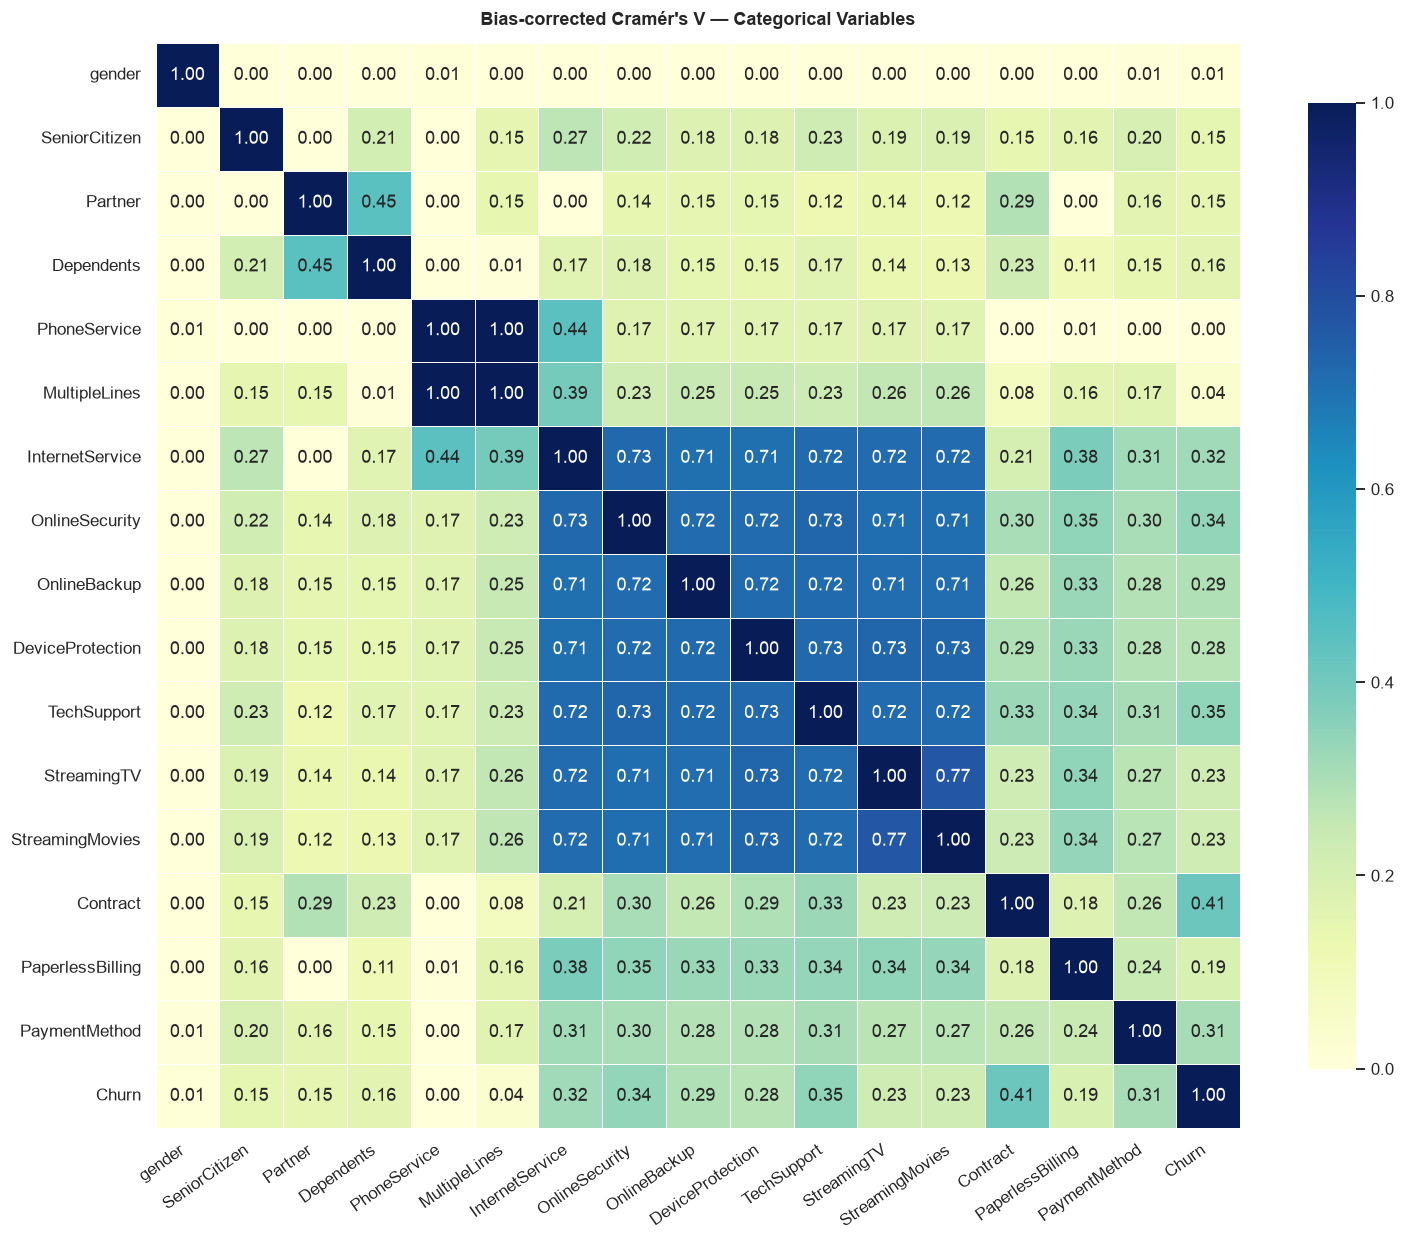

,bias_corrected_v,conventional_v
Contract,0.4121,0.4125
TechSupport,0.3451,0.3456
OnlineSecurity,0.3420,0.3424
InternetService,0.3179,0.3185
PaymentMethod,0.3051,0.3059
OnlineBackup,0.2919,0.2925
DeviceProtection,0.2788,0.2794
StreamingMovies,0.2298,0.2305
StreamingTV,0.2268,0.2275
PaperlessBilling,0.1922,0.1927


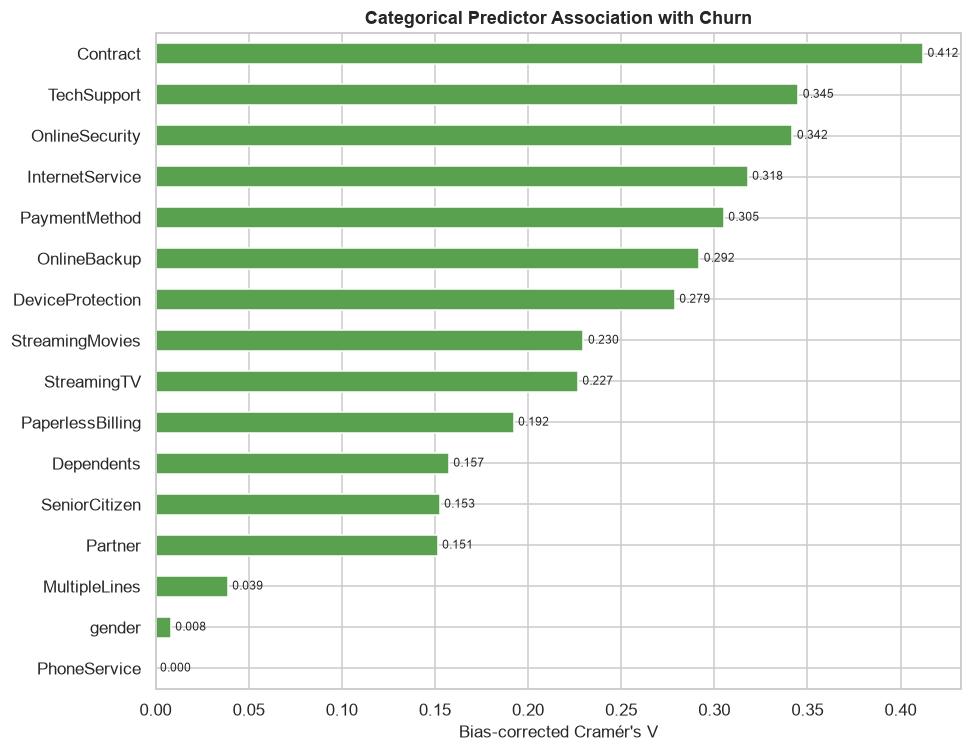

In [9]:
# ruff: noqa: E501
annotated_heatmap(cramers_corrected, "Bias-corrected Cramér's V — Categorical Variables", cmap="YlGnBu", center=None, vmin=0, vmax=1, figsize=(14, 12), fmt=".2f")

cramers_target = pd.DataFrame({
    "bias_corrected_v": cramers_corrected.loc[categorical_features, target_column],
    "conventional_v": cramers_conventional.loc[categorical_features, target_column],
}).sort_values("bias_corrected_v", ascending=True)
display(cramers_target.sort_values("bias_corrected_v", ascending=False))

fig, axis = plt.subplots(figsize=(9, 7))
cramers_target["bias_corrected_v"].plot.barh(ax=axis, color="#59A14F")
axis.set(title="Categorical Predictor Association with Churn", xlabel="Bias-corrected Cramér's V", ylabel="")
axis.bar_label(axis.containers[0], fmt="%.3f", padding=3, fontsize=8)
plt.tight_layout()
plt.show()

In [10]:
# ruff: noqa: E501
structural_pairs = [
    ("PhoneService", "MultipleLines"),
    ("InternetService", "OnlineSecurity"),
    ("InternetService", "OnlineBackup"),
    ("InternetService", "DeviceProtection"),
    ("InternetService", "TechSupport"),
    ("InternetService", "StreamingTV"),
    ("InternetService", "StreamingMovies"),
    ("Contract", "PaymentMethod"),
    ("OnlineSecurity", "TechSupport"),
]
structural_association_table = pd.DataFrame([
    {"feature_1": left, "feature_2": right, "bias_corrected_v": cramers_corrected.loc[left, right], "conventional_v": cramers_conventional.loc[left, right]}
    for left, right in structural_pairs
]).sort_values("bias_corrected_v", ascending=False)
display(structural_association_table)

for left, right in [("PhoneService", "MultipleLines"), ("InternetService", "OnlineSecurity"), ("Contract", "PaymentMethod"), ("OnlineSecurity", "TechSupport")]:
    print(f"\n{left} × {right}")
    display(pd.crosstab(df[left], df[right], margins=True))

,feature_1,feature_2,bias_corrected_v,conventional_v
0,PhoneService,MultipleLines,0.9999,1.0000
8,OnlineSecurity,TechSupport,0.7323,0.7324
1,InternetService,OnlineSecurity,0.7252,0.7253
4,InternetService,TechSupport,0.7218,0.7219
5,InternetService,StreamingTV,0.7169,0.7171
6,InternetService,StreamingMovies,0.7153,0.7154
2,InternetService,OnlineBackup,0.7070,0.7071
3,InternetService,DeviceProtection,0.7070,0.7071
7,Contract,PaymentMethod,0.2596,0.2606



PhoneService × MultipleLines


MultipleLines,No,No phone service,Yes,All
PhoneService,,,,
No,0,529,0,529
Yes,2730,0,2375,5105
All,2730,529,2375,5634



InternetService × OnlineSecurity


OnlineSecurity,No,No internet service,Yes,All
InternetService,,,,
DSL,989,0,945,1934
Fiber optic,1827,0,666,2493
No,0,1207,0,1207
All,2816,1207,1611,5634



Contract × PaymentMethod


PaymentMethod,Bank transfer (automatic),Credit card (automatic),Electronic check,Mailed check,All
Contract,,,,,
Month-to-month,482,438,1462,713,3095
One year,314,313,270,281,1178
Two year,450,464,145,302,1361
All,1246,1215,1877,1296,5634



OnlineSecurity × TechSupport


TechSupport,No,No internet service,Yes,All
OnlineSecurity,,,,
No,2050,0,766,2816
No internet service,0,1207,0,1207
Yes,736,0,875,1611
All,2786,1207,1641,5634


**Observed categorical findings.** Contract has the largest target association
($V_c=0.412$), followed by TechSupport (0.345), OnlineSecurity (0.342), InternetService
(0.318), PaymentMethod (0.305), and OnlineBackup (0.292). PhoneService is effectively zero
with churn after correction; V has no sign, so it cannot say which category is higher risk.

PhoneService–MultipleLines is structurally deterministic ($V_c=1.000$ rounded): every
customer without phone service receives `No phone service`. InternetService–dependent
service values are also structurally linked (roughly 0.707–0.725) because `No internet
service` is inherited when internet is absent, but subscriber adoption still varies.
OnlineSecurity–TechSupport is 0.732: part is the shared structural state and part is
empirical co-adoption, so it merits subscriber-only follow-up rather than automatic
deduplication. Contract–PaymentMethod is 0.260, an empirical relationship rather than a
definition. Structural dependencies are expected data semantics; unexpected redundancy
would be strong overlap not explained by feature definitions.

# 8. Phi coefficient for genuinely binary variables

For a $2\times2$ table with counts $a,b,c,d$,

$$\phi=\frac{ad-bc}{\sqrt{(a+b)(c+d)(a+c)(b+d)}}.$$

Phi equals Pearson correlation between two binary variables. Unlike Cramér's V it is
signed, but the sign depends entirely on documented 0/1 orientation. We include only
genuinely binary predictors—no multicategory feature is collapsed or arbitrarily
binarized. Mappings below use `No/Female=0`, `Yes/Male=1`, and `Churn No=0, Yes=1`;
`SeniorCitizen` retains its documented 0/1 coding.

gender              {'Female': 0, 'Male': 1}
SeniorCitizen                   {0: 0, 1: 1}
Partner                  {'No': 0, 'Yes': 1}
Dependents               {'No': 0, 'Yes': 1}
PhoneService             {'No': 0, 'Yes': 1}
PaperlessBilling         {'No': 0, 'Yes': 1}
Churn                    {'No': 0, 'Yes': 1}
Name: 0/1 mapping, dtype: object

,gender,SeniorCitizen,Partner,Dependents,PhoneService,PaperlessBilling,Churn
gender,1.0000,0.0007,0.0025,0.0057,-0.0162,-0.0061,-0.0156
SeniorCitizen,0.0007,1.0000,0.0108,-0.2127,-0.0012,0.1582,0.1531
Partner,0.0025,0.0108,1.0000,0.4475,0.0138,-0.0061,-0.1520
Dependents,0.0057,-0.2127,0.4475,1.0000,0.0007,-0.1089,-0.1580
PhoneService,-0.0162,-0.0012,0.0138,0.0007,1.0000,0.0148,0.0088
PaperlessBilling,-0.0061,0.1582,-0.0061,-0.1089,0.0148,1.0000,0.1927
Churn,-0.0156,0.1531,-0.1520,-0.1580,0.0088,0.1927,1.0000


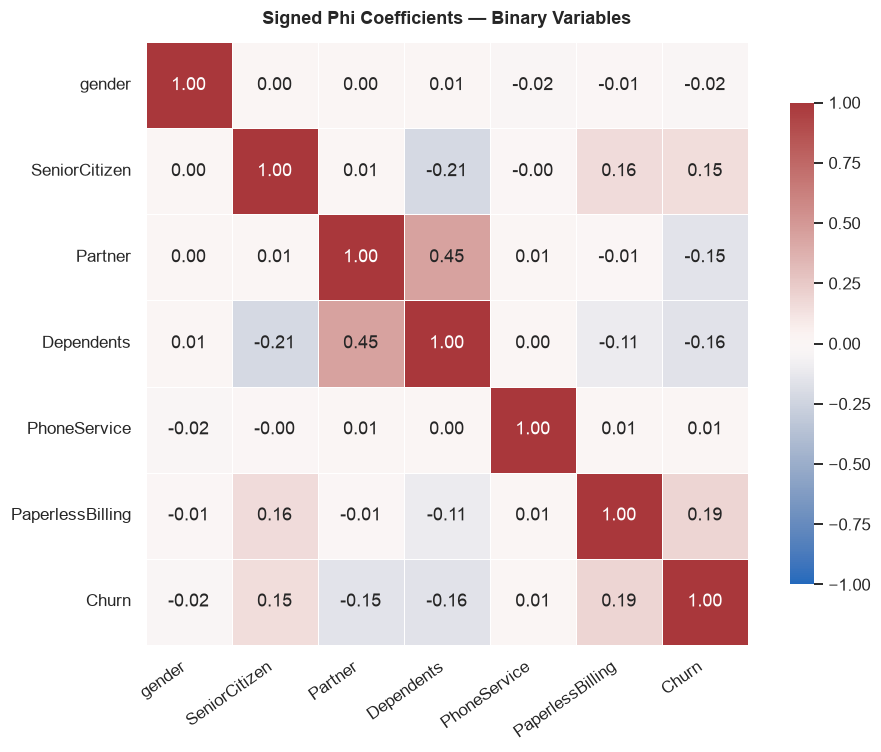

In [11]:
# ruff: noqa: E501
binary_mappings = {
    "gender": {"Female": 0, "Male": 1},
    "SeniorCitizen": {0: 0, 1: 1},
    "Partner": {"No": 0, "Yes": 1},
    "Dependents": {"No": 0, "Yes": 1},
    "PhoneService": {"No": 0, "Yes": 1},
    "PaperlessBilling": {"No": 0, "Yes": 1},
    target_column: {"No": 0, "Yes": 1},
}
binary_data = pd.DataFrame({column: df[column].map(mapping) for column, mapping in binary_mappings.items()})
assert binary_data.notna().all().all()
phi_matrix = binary_data.corr(method="pearson")
assert_symmetric_association(phi_matrix)
display(pd.Series({column: f"{mapping}" for column, mapping in binary_mappings.items()}, name="0/1 mapping"))
display(phi_matrix)
annotated_heatmap(phi_matrix, "Signed Phi Coefficients — Binary Variables", figsize=(9, 7), fmt=".2f")

**Observed Phi findings versus churn.** PaperlessBilling has the largest positive Phi
($+0.193$), followed by SeniorCitizen ($+0.153$). Dependents ($-0.158$) and Partner
($-0.152$) are negative under `Yes=1`; gender ($-0.016$) and PhoneService ($+0.009$) are
near zero. Reversing either variable's mapping reverses the sign without changing
association strength, so orientation must always accompany interpretation.

# 9. Correlation ratio (Eta): categorical versus numerical

For numerical $Y$ grouped by categorical $X$, the correlation ratio is

$$\eta^2(Y\mid X)=\frac{\sum_g n_g(\bar y_g-\bar y)^2}
{\sum_i(y_i-\bar y)^2},\qquad \eta=\sqrt{\eta^2}.$$

Eta-squared is the share of total numerical variability attributable to between-group
mean differences; Eta is its square root. It can capture group-dependent numerical means
without assigning order to categories. It is directional in variable roles—category
groups explain variation in a number—but it is nonnegative and supplies no positive or
negative sign. It can miss distributional differences with equal means and does not imply
causality.

,tenure,MonthlyCharges,TotalCharges
gender,0.0070,0.0141,0.0009
SeniorCitizen,0.0174,0.2174,0.0985
Partner,0.3707,0.0980,0.3114
Dependents,0.1476,0.1050,0.0598
PhoneService,0.0126,0.2461,0.1151
MultipleLines,0.3452,0.5062,0.4718
InternetService,0.0457,0.9064,0.4316
OnlineSecurity,0.3378,0.7662,0.4822
OnlineBackup,0.3802,0.7839,0.5501
DeviceProtection,0.3727,0.7923,0.5543


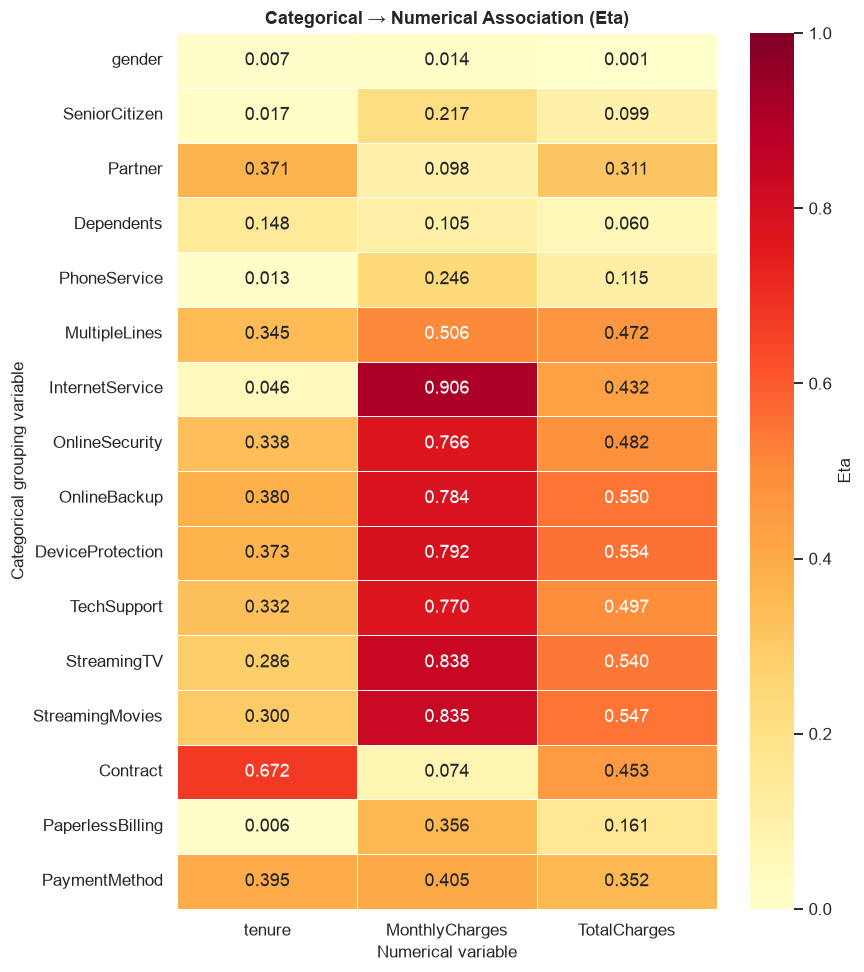

,categorical,numerical,eta,eta_squared
0,Contract,tenure,0.6723,0.4520
1,InternetService,MonthlyCharges,0.9064,0.8215
2,PaymentMethod,tenure,0.3954,0.1564
3,Contract,TotalCharges,0.4534,0.2056


In [12]:
# ruff: noqa: E501
def correlation_ratio(categories: pd.Series, values: pd.Series) -> float:
    # Calculate eta safely for categorical groups and finite numerical values.
    codes, _ = pd.factorize(categories, sort=False)
    numeric = pd.to_numeric(values, errors="coerce").to_numpy(dtype=float)
    valid = (codes >= 0) & np.isfinite(numeric)
    codes, numeric = codes[valid], numeric[valid]
    if numeric.size == 0:
        return 0.0
    total_sum_squares = np.sum((numeric - numeric.mean()) ** 2)
    if total_sum_squares <= 0:
        return 0.0
    between_sum_squares = 0.0
    for group in np.unique(codes):
        group_values = numeric[codes == group]
        between_sum_squares += group_values.size * (group_values.mean() - numeric.mean()) ** 2
    return float(np.sqrt(max(0.0, between_sum_squares / total_sum_squares)))


eta_matrix = pd.DataFrame({number: {category: correlation_ratio(df[category], df[number]) for category in categorical_features} for number in numerical_features})
assert ((eta_matrix >= 0) & (eta_matrix <= 1)).all().all()
display(eta_matrix)

fig, axis = plt.subplots(figsize=(8, 9))
sns.heatmap(eta_matrix, annot=True, fmt=".3f", cmap="YlOrRd", vmin=0, vmax=1, linewidths=0.5, cbar_kws={"label": "Eta"}, ax=axis)
axis.set_title("Categorical → Numerical Association (Eta)")
axis.set(xlabel="Numerical variable", ylabel="Categorical grouping variable")
plt.tight_layout()
plt.show()

selected_eta = pd.DataFrame([
    {"categorical": category, "numerical": number, "eta": eta_matrix.loc[category, number], "eta_squared": eta_matrix.loc[category, number] ** 2}
    for category, number in [("Contract", "tenure"), ("InternetService", "MonthlyCharges"), ("PaymentMethod", "tenure"), ("Contract", "TotalCharges")]
])
display(selected_eta)

**Observed Eta findings.** InternetService strongly separates MonthlyCharges
($\eta=0.906$, $\eta^2=0.822$), matching the earlier medians of 20.10 for no internet,
56.35 for DSL, and 91.85 for fibre. StreamingTV (0.838) and StreamingMovies (0.835) also
strongly separate price, partly because their structural no-internet state identifies the
low-price group. Contract–tenure is substantial (0.672; 45.2% between-group variance).
PaymentMethod–tenure is 0.395, and Contract–TotalCharges is 0.453. These quantify group
mean separation, not signed effects or intervention value.

# 10. Exploratory feature–target mutual information

Shannon entropy is $H(Y)=-\sum_y p(y)\log p(y)$; conditional entropy is the remaining
uncertainty after observing $X$. Mutual information is

$$I(X;Y)=H(Y)-H(Y\mid X)=\sum_{x,y}p(x,y)\log\frac{p(x,y)}{p(x)p(y)}.$$

MI is nonnegative and can detect nonlinear, non-monotonic dependency, unlike signed
correlation. It has no direction or causal meaning. Estimation can be biased and sensitive
to sample size, neighbor count, discrete declarations, continuous-value ties, and random
jitter. Marginal MI can miss interaction-only predictors whose information appears only
jointly.

`tenure` is declared discrete because it records completed months with 73 observed values,
not a continuous measurement. MonthlyCharges and TotalCharges use the continuous k-nearest
neighbor estimator. Nominal predictors and SeniorCitizen use temporary category codes and
are explicitly marked discrete. Settings are `n_neighbors=3` and configured
`random_state=42`. This is exploratory association—not final feature selection; any later
selection must be refitted inside training folds.

,mutual_information_nats
Contract,0.0994
tenure,0.0800
TechSupport,0.0639
OnlineSecurity,0.0629
InternetService,0.0543
TotalCharges,0.0497
OnlineBackup,0.0467
PaymentMethod,0.0452
MonthlyCharges,0.0447
DeviceProtection,0.0432


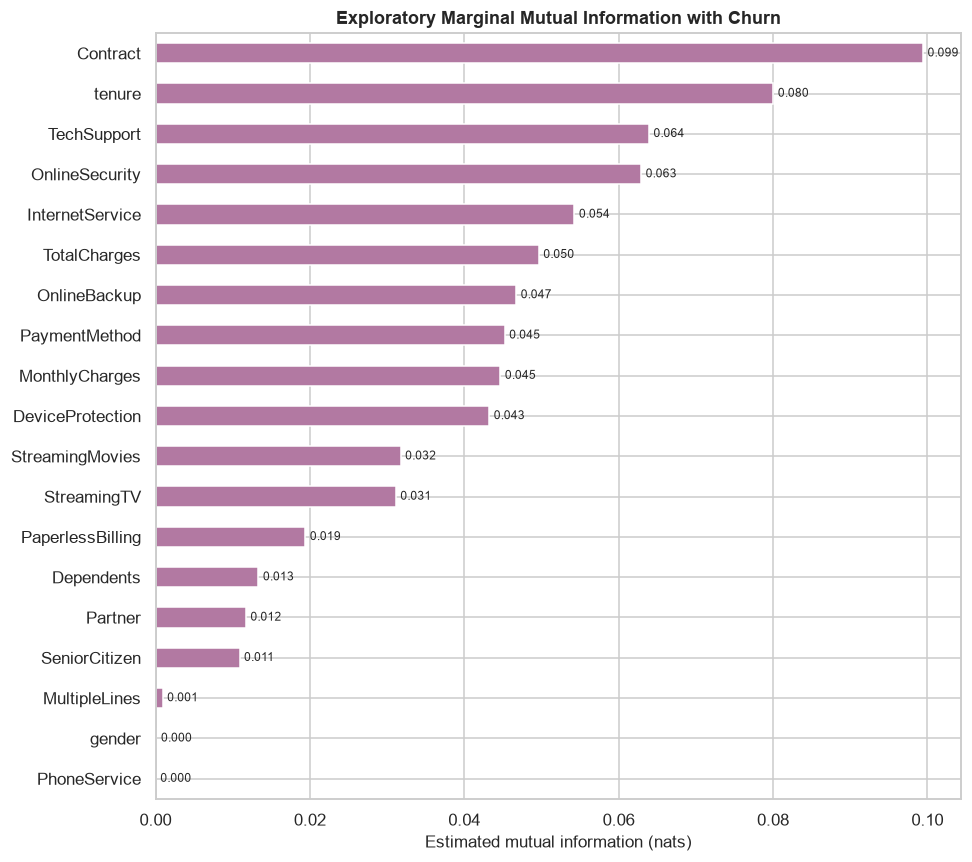

In [13]:
# ruff: noqa: E501
mi_data = pd.DataFrame(index=df.index)
for feature in predictor_features:
    if feature in categorical_features:
        mi_data[feature] = df[feature].astype("category").cat.codes
    else:
        mi_data[feature] = df[feature]

discrete_mask = np.array([feature == "tenure" or feature in categorical_features for feature in predictor_features])
mutual_information_values = mutual_info_classif(
    mi_data,
    churn_binary,
    discrete_features=discrete_mask,
    n_neighbors=3,
    random_state=random_state,
)
mutual_information = pd.Series(mutual_information_values, index=predictor_features, name="mutual_information_nats").sort_values(ascending=True)
display(mutual_information.sort_values(ascending=False).to_frame())

fig, axis = plt.subplots(figsize=(9, 8))
mutual_information.plot.barh(ax=axis, color="#B279A2")
axis.set(title="Exploratory Marginal Mutual Information with Churn", xlabel="Estimated mutual information (nats)", ylabel="")
axis.bar_label(axis.containers[0], fmt="%.3f", padding=3, fontsize=8)
plt.tight_layout()
plt.show()

**Observed exploratory MI ranking.** Contract leads (0.099 nats), followed by tenure
(0.080), TechSupport (0.064), OnlineSecurity (0.063), InternetService (0.054), TotalCharges
(0.050), OnlineBackup (0.047), PaymentMethod (0.045), MonthlyCharges (0.045), and
DeviceProtection (0.043). PhoneService, gender, and MultipleLines are near zero marginally.
Values are estimator- and sample-dependent and are not a validated feature-selection rule.

# 11. Feature redundancy screening

The documented exploratory heuristics are $|r|\ge0.80$ for Pearson or Spearman,
bias-corrected Cramér's $V\ge0.80$, and $\eta\ge0.80$. They are screening thresholds,
not universal laws. A flagged pair is investigated, not automatically dropped.

In [14]:
# ruff: noqa: E501
redundancy_rows = []
for measure_name, matrix in [("Pearson |r|", pearson_matrix.abs()), ("Spearman |rho|", spearman_matrix.abs())]:
    for left_index, left in enumerate(numerical_features):
        for right in numerical_features[left_index + 1:]:
            if matrix.loc[left, right] >= 0.80:
                redundancy_rows.append({"feature_1": left, "feature_2": right, "measure": measure_name, "magnitude": matrix.loc[left, right], "dependency_type": "Empirical with billing structure"})
for left_index, left in enumerate(categorical_features):
    for right in categorical_features[left_index + 1:]:
        if cramers_corrected.loc[left, right] >= 0.80:
            redundancy_rows.append({"feature_1": left, "feature_2": right, "measure": "Bias-corrected Cramér's V", "magnitude": cramers_corrected.loc[left, right], "dependency_type": "Structural"})
for category in categorical_features:
    for number in numerical_features:
        if eta_matrix.loc[category, number] >= 0.80:
            redundancy_rows.append({"feature_1": category, "feature_2": number, "measure": "Eta", "magnitude": eta_matrix.loc[category, number], "dependency_type": "Structural/product-mix + empirical"})

redundancy_report = pd.DataFrame(redundancy_rows).sort_values(["magnitude", "measure"], ascending=[False, True]).reset_index(drop=True)
display(redundancy_report)

,feature_1,feature_2,measure,magnitude,dependency_type
0,PhoneService,MultipleLines,Bias-corrected Cramér's V,0.9999,Structural
1,InternetService,MonthlyCharges,Eta,0.9064,Structural/product-mix + empirical
2,tenure,TotalCharges,Spearman |rho|,0.8915,Empirical with billing structure
3,StreamingTV,MonthlyCharges,Eta,0.8377,Structural/product-mix + empirical
4,StreamingMovies,MonthlyCharges,Eta,0.8353,Structural/product-mix + empirical
5,tenure,TotalCharges,Pearson |r|,0.8290,Empirical with billing structure


**Flagged relationships and implications.**

- **PhoneService–MultipleLines:** corrected V 1.000; structural because `No phone service`
  is encoded in MultipleLines. Linear models need careful reference coding to avoid exact
  dummy dependencies; trees may repeatedly split on interchangeable structural signals.
- **tenure–TotalCharges:** Pearson 0.829 and Spearman 0.892; accumulated charges combine
  exposure duration with price. Linear coefficients may become unstable or conditional
  interpretations may shift; trees can distribute importance across the pair. The
  relationship merits residual/product-form diagnostics later, not automatic deletion.
- **InternetService–MonthlyCharges:** Eta 0.906; service type strongly defines price bands.
  This is product architecture plus empirical price variation. Both variables can still
  carry different information about churn.
- **StreamingTV–MonthlyCharges (0.838) and StreamingMovies–MonthlyCharges (0.835):** the
  structural no-internet state and paid-service bundles separate prices. Linear models need
  stable encoding and interaction checks; trees can share importance among correlated
  bundle indicators. Subscriber-only analysis can separate eligibility from adoption.

Internet-dependent feature pairs around V 0.71–0.73 do not cross the 0.80 screen but remain
known structural dependencies. OnlineSecurity–TechSupport (0.732) is notable empirical
co-adoption plus shared eligibility and deserves follow-up. No predictor is removed and no
VIF is calculated.

# 12. Separate feature–target association summaries

The rankings below remain separate because their scales and estimands differ. Point-biserial
is a signed standardized mean relationship, Cramér's V is unsigned categorical dependence,
and MI is an unsigned entropy reduction estimate. Combining them into one score would imply
a false common unit.

Correlation/association describes marginal dependence; predictive feature importance
describes a fitted model's use of information conditional on other inputs and a chosen loss.
Neither is automatically causal.

In [15]:
# ruff: noqa: E501
numerical_target_ranking = point_biserial.rename("signed_point_biserial_r").to_frame()
categorical_target_ranking = cramers_target.sort_values("bias_corrected_v", ascending=False)
all_feature_mi_ranking = mutual_information.sort_values(ascending=False).to_frame()

print("Numerical predictors — signed point-biserial correlation")
display(numerical_target_ranking)
print("Categorical predictors — Cramér's V")
display(categorical_target_ranking)
print("All predictors — exploratory mutual information")
display(all_feature_mi_ranking)

Numerical predictors — signed point-biserial correlation


,signed_point_biserial_r
tenure,-0.3519
TotalCharges,-0.2010
MonthlyCharges,0.1889


Categorical predictors — Cramér's V


,bias_corrected_v,conventional_v
Contract,0.4121,0.4125
TechSupport,0.3451,0.3456
OnlineSecurity,0.3420,0.3424
InternetService,0.3179,0.3185
PaymentMethod,0.3051,0.3059
OnlineBackup,0.2919,0.2925
DeviceProtection,0.2788,0.2794
StreamingMovies,0.2298,0.2305
StreamingTV,0.2268,0.2275
PaperlessBilling,0.1922,0.1927


All predictors — exploratory mutual information


,mutual_information_nats
Contract,0.0994
tenure,0.0800
TechSupport,0.0639
OnlineSecurity,0.0629
InternetService,0.0543
TotalCharges,0.0497
OnlineBackup,0.0467
PaymentMethod,0.0452
MonthlyCharges,0.0447
DeviceProtection,0.0432


## Comparison with Steps 8–9

- **Contract and tenure:** Contract leads categorical V and MI; tenure leads absolute
  numerical target correlation and ranks second in MI. This supports the earlier strong
  contract/lifecycle patterns while retaining the confounding warning.
- **Electronic check:** PaymentMethod ranks fifth by categorical V (0.305) and eighth by
  MI (0.045). The elevated electronic-check rate persists as association, not causation.
- **Fibre optic:** InternetService ranks fourth by V (0.318) and fifth by MI (0.054),
  consistent with prior fibre churn and price separation; Eta confirms service–price
  structure rather than isolating a fibre effect.
- **Security and support:** TechSupport and OnlineSecurity rank second and third by V and
  third and fourth by MI. Their mutual V of 0.732 reflects both eligibility and co-adoption,
  matching the prior joint support/security finding without proving intervention benefit.
- **Monthly charges:** its positive point-biserial coefficient is 0.189 and MI is 0.045.
  It associates with churn but is below tenure on the numerical signed ranking and strongly
  entangled with service/bundle groups by Eta.

The measures need not reproduce identical orders: they capture different variable types
and aspects of dependence, and none is conditional model importance.

# 13. Business and machine-learning implications

The strongest business signals cluster around commitment, lifecycle, internet product
mix, support/security adoption, and billing method. Retention analysis should distinguish
addressable behavior from structural eligibility and customer self-selection. Association
does not prove that moving a customer to a longer contract, automatic payment, or a support
service will reduce churn.

For later modelling, use fold-fitted preprocessing, preserve structural categories, and
monitor coefficient stability and importance sharing. Linear models may need deliberate
reference levels, regularization, and nonlinear/interaction terms; tree models tolerate
nonlinearity but can split importance among redundant predictors and overuse structural
shortcuts. Any feature removal or MI-based selection must be validated within training
folds against out-of-fold utility and stability.

# 14. Interview questions with speakable answers

### 1. Why are Pearson and Spearman different for tenure and TotalCharges?

**Speakable answer:** “Pearson is 0.829 and measures a straight-line relationship, while
Spearman is 0.892 and measures whether ranks increase together. Total charges generally
rise with tenure, but monthly price creates a fan-shaped spread, so the monotonic ordering
is stronger than a single linear fit. Tied tenure ranks and possible value extremes also
affect the difference; I would not claim nonlinearity from the coefficient gap alone.”

### 2. Why is PhoneService–MultipleLines almost one, and should one feature be dropped?

**Speakable answer:** “MultipleLines contains `No phone service`, so phone eligibility is
embedded by definition. That creates structural rather than surprising redundancy. I
would preserve semantics, inspect the encoding design, and compare fold-validated models.
In a linear model I would avoid exact dummy dependence; in a tree model I would expect
importance sharing. A high association is a review flag, not an automatic drop rule.”

### 3. Why not compare Cramér's V 0.41 directly with point-biserial 0.35?

**Speakable answer:** “They have different estimands. Cramér's V is unsigned dependence
from a contingency table and can handle multicategory variables. Point-biserial is a signed
standardized mean relationship between a number and binary target. The numerical values do
not share a common practical scale, so I keep separate rankings and interpret each using
its variable type and business context.”

### 4. Can mutual information be used to select the final features here?

**Speakable answer:** “No. These are marginal, sample-dependent estimates. MI can detect
nonlinear dependence but can miss interaction-only predictors, share information among
redundant features, and change with discrete declarations and neighbor settings. Any
selection must be refitted inside each training fold and judged through out-of-fold model
performance, stability, and business cost. High MI also does not imply causation.”

# 15. Verification, leakage audit, and limitations

The final cell checks path scope, row preservation, safe behavior for constant inputs and
zero denominators, matrix invariants, temporary encodings, configured randomness, and the
unchanged SHA-256 hashes of all four previous notebooks.

In [16]:
# ruff: noqa: E501
expected_previous_hashes = {
    "01_exploratory_data_analysis.ipynb": "970288d8018d13770f972835b4ecc86fe7857e28c0b7447b104fa5b3edcf662b",
    "02_univariate_analysis.ipynb": "0fb866bc140e43c42372e7c13af8712d78ab5b0f49d8edef76e26d61b851de4a",
    "03_bivariate_analysis.ipynb": "1ec80ddc2eb412b604841a20afa78e5199903ff00206f4e291a48a16d655d495",
    "04_multivariate_analysis.ipynb": "4bc0c85cdc2f8314b4d68ef1954e7b4c03b44902137b0ff01afbe3d596573331",
}
observed_previous_hashes = {
    name: hashlib.sha256((PROJECT_ROOT / "notebooks" / name).read_bytes()).hexdigest()
    for name in expected_previous_hashes
}

assert development_path == (PROJECT_ROOT / "data/processed/development.parquet").resolve()
assert development_path.name not in {"test.parquet", "validated.parquet"}
assert len(df) == 5_634 and df.index.is_unique
assert random_state == 42
assert churn_binary.name == target_column and set(churn_binary.unique()) == {0, 1}
assert target_column not in mi_data.columns and identifier_column not in mi_data.columns
assert list(mi_data.columns) == predictor_features
assert correlation_ratio(pd.Series(["one", "one", "two"]), pd.Series([5.0, 5.0, 5.0])) == 0.0
assert cramers_v(pd.Series(["constant"] * 4), pd.Series(["a", "b", "a", "b"])) == 0.0
assert_symmetric_association(pearson_matrix)
assert_symmetric_association(spearman_matrix)
assert_symmetric_association(kendall_matrix)
assert_symmetric_association(cramers_corrected)
assert_symmetric_association(phi_matrix)
assert observed_previous_hashes == expected_previous_hashes

print("All notebook verification checks passed.")
print("Loaded data source:", development_path.relative_to(PROJECT_ROOT))
print("Held-out test and complete validated datasets were not accessed.")
display(pd.DataFrame({"expected_sha256": expected_previous_hashes, "observed_sha256": observed_previous_hashes}))

All notebook verification checks passed.
Loaded data source: data/processed/development.parquet
Held-out test and complete validated datasets were not accessed.


,expected_sha256,observed_sha256
01_exploratory_data_analysis.ipynb,970288d8018d13770f972835b4ecc86fe7857e28c0b744...,970288d8018d13770f972835b4ecc86fe7857e28c0b744...
02_univariate_analysis.ipynb,0fb866bc140e43c42372e7c13af8712d78ab5b0f49d8ed...,0fb866bc140e43c42372e7c13af8712d78ab5b0f49d8ed...
03_bivariate_analysis.ipynb,1ec80ddc2eb412b604841a20afa78e5199903ff00206f4...,1ec80ddc2eb412b604841a20afa78e5199903ff00206f4...
04_multivariate_analysis.ipynb,4bc0c85cdc2f8314b4d68ef1954e7b4c03b44902137b0f...,4bc0c85cdc2f8314b4d68ef1954e7b4c03b44902137b0f...


## Remaining limitations

- This is a static development sample without time order, intervention assignment, plan
  history, retention cost, or causal identification.
- Pairwise measures are marginal and can be confounded; they do not isolate conditional
  effects or interactions.
- Pearson and mean-based Eta can miss other distributional structure; rank measures lose
  metric distance; Cramér's V has no direction; Phi signs depend on mapping.
- Categorical association can be influenced by structural service states, while sparse
  future categories may be less stable than this development sample suggests.
- MI depends on estimator settings and discrete/continuous declarations.
- No uncertainty intervals, p-values, hypothesis tests, VIF, outlier analysis, feature
  removal, final selection, balancing, or predictive modelling is performed.